# THỰC HÀNH 02 – PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
**Trường Đại học Sài Gòn – Môn: Khai thác dữ liệu**

Notebook này gồm các **Bài tập thực hành 2** của 3 phần:

| Phần | Nội dung | Dữ liệu |
|---|---|---|
| 1 | Thống kê mô tả (mục 1.1.4) | Diabetes |
| 2 | Trực quan hóa & EDA (mục 1.2.3) |Diabetes + Online Retail |
| 3 | Công cụ EDA tự động – AutoViz (mục 1.3.4) | Marketing Campaign |

**Dữ liệu cần chuẩn bị** (đặt trong thư mục `./data`):
- `diabetes.csv` – https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
- `Online_Retail.xlsx` (hoặc `Online Retail.xlsx`, `OnlineRetail.csv`, `data.csv`) – https://www.kaggle.com/code/rajatkumar30/eda-online-retail (dataset Online Retail của UCI)
- `marketing_campaign.csv` – https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

import os, glob, re

def _norm(n):
    """Chuẩn hóa tên file: bỏ dấu cách/gạch dưới/gạch ngang, không phân biệt hoa thường."""
    return re.sub(r"[\s_\-]+", "", n).lower()

def find_file(*candidates):
    """Tìm file dữ liệu trong thư mục hiện tại, ./data, ./Data, /mnt/user-data/uploads hoặc /kaggle/input.
    Chấp nhận tên khác nhau về dấu cách / gạch dưới / hoa thường (vd 'Online Retail.xlsx' ~ 'Online_Retail.xlsx')."""
    folders = [".", "data", "Data", "/mnt/user-data/uploads", "/kaggle/input"]
    for name in candidates:
        for f in folders:
            p = os.path.join(f, name)
            if os.path.exists(p):
                return p
    for name in candidates:
        for f in folders:
            if not os.path.isdir(f):
                continue
            for root, _, files in os.walk(f):
                for fn in files:
                    if _norm(fn) == _norm(name):
                        return os.path.join(root, fn)
    raise FileNotFoundError(f"Không tìm thấy {candidates}. Hãy đặt file dữ liệu vào thư mục ./data")


---
# PHẦN 1. THỐNG KÊ MÔ TẢ – PIMA INDIANS DIABETES
## 1.1 Nạp dữ liệu và quan sát tổng quan
Các cột: `Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age, Outcome` (Outcome: 1 = có tiểu đường).

In [22]:
diab = pd.read_csv(find_file("diabetes.csv"))
print("Kích thước:", diab.shape)
diab.head()

Kích thước: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [23]:
diab.info()
print("\nGiá trị thiếu (NaN):\n", diab.isnull().sum())
print("\nSố dòng trùng:", diab.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Giá trị thiếu (NaN):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age               

## 1.2 Phát hiện "giá trị thiếu ẩn"
Trong bộ dữ liệu này, các cột `Glucose, BloodPressure, SkinThickness, Insulin, BMI` **không thể bằng 0** về mặt y khoa → số 0 thực chất là dữ liệu thiếu được mã hóa.

In [24]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_cnt = (diab[zero_cols] == 0).sum()
pd.DataFrame({"số giá trị 0": zero_cnt, "% ": (zero_cnt / len(diab) * 100).round(2)})

,số giá trị 0,%
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


In [25]:
# Thay 0 bằng NaN, sau đó điền bằng median theo từng nhóm Outcome
diab_clean = diab.copy()
diab_clean[zero_cols] = diab_clean[zero_cols].replace(0, np.nan)
print("Số NaN sau khi thay:\n", diab_clean.isnull().sum(), "\n")

for c in zero_cols:
    diab_clean[c] = diab_clean[c].fillna(diab_clean.groupby("Outcome")[c].transform("median"))

print("Số NaN sau khi điền median theo nhóm:", diab_clean.isnull().sum().sum())

Số NaN sau khi thay:
 Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64 

Số NaN sau khi điền median theo nhóm: 0


## 1.3 Các thước đo thống kê mô tả (numpy + scipy.stats)

In [26]:
col = "Glucose"
x = diab_clean[col]

m = stats.mode(x, keepdims=False)
q1, q2, q3 = np.quantile(x, [0.25, 0.5, 0.75])
print(f"Biến: {col}")
print(f"Mean         : {np.mean(x):.3f}")
print(f"Median       : {np.median(x):.3f}")
print(f"Mode         : {m.mode} ({m.count} lần)")
print(f"Variance     : {np.var(x):.3f}")
print(f"Std          : {np.std(x):.3f}")
print(f"Min/Max/Range: {x.min()} / {x.max()} / {x.max() - x.min()}")
print(f"P60          : {np.percentile(x, 60):.3f}")
print(f"Q1/Q2/Q3     : {q1} / {q2} / {q3}")
print(f"IQR          : {stats.iqr(x):.3f}")

Biến: Glucose
Mean         : 121.677
Median       : 117.000
Mode         : 99.0 (17 lần)
Variance     : 926.857
Std          : 30.444
Min/Max/Range: 44.0 / 199.0 / 155.0
P60          : 125.000
Q1/Q2/Q3     : 99.75 / 117.0 / 140.25
IQR          : 40.500


In [27]:
num_cols = diab_clean.columns.drop("Outcome")

summary = pd.DataFrame({
    "mean": diab_clean[num_cols].mean(),
    "median": diab_clean[num_cols].median(),
    "mode": diab_clean[num_cols].mode().iloc[0],
    "variance": diab_clean[num_cols].var(),
    "std": diab_clean[num_cols].std(),
    "min": diab_clean[num_cols].min(),
    "max": diab_clean[num_cols].max(),
    "range": diab_clean[num_cols].max() - diab_clean[num_cols].min(),
    "Q1": diab_clean[num_cols].quantile(0.25),
    "Q3": diab_clean[num_cols].quantile(0.75),
    "IQR": diab_clean[num_cols].apply(stats.iqr),
    "skewness": diab_clean[num_cols].skew(),
    "kurtosis": diab_clean[num_cols].kurt(),
})
summary.round(3)

,mean,median,mode,variance,std,min,max,range,Q1,Q3,IQR,skewness,kurtosis
Pregnancies,3.845,3.000,1.000,11.354,3.370,0.000,17.00,17.000,1.000,6.000,5.000,0.902,0.159
Glucose,121.677,117.000,99.000,928.065,30.464,44.000,199.00,155.000,99.750,140.250,40.500,0.532,-0.268
BloodPressure,72.389,72.000,70.000,146.556,12.106,24.000,122.00,98.000,64.000,80.000,16.000,0.141,1.085
SkinThickness,29.090,28.000,27.000,79.047,8.891,7.000,99.00,92.000,25.000,32.000,7.000,0.817,5.068
Insulin,141.754,102.500,102.500,7938.961,89.101,14.000,846.00,832.000,102.500,169.500,67.000,3.028,13.853
BMI,32.435,32.050,30.100,47.341,6.880,18.200,67.10,48.900,27.500,36.600,9.100,0.606,0.915
DiabetesPedigreeFunction,0.472,0.372,0.254,0.110,0.331,0.078,2.42,2.342,0.244,0.626,0.382,1.920,5.595
Age,33.241,29.000,22.000,138.303,11.760,21.000,81.00,60.000,24.000,41.000,17.000,1.130,0.643


## 1.4 Thống kê theo nhóm `Outcome`

In [28]:
print("Tỉ lệ Outcome:")
print(diab_clean["Outcome"].value_counts(normalize=True).round(3))
print()
diab_clean.groupby("Outcome")[list(num_cols)].agg(["mean", "median", "std"]).T.round(2)

Tỉ lệ Outcome:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64



Outcome                               0       1
Pregnancies              mean      3.30    4.87
                         median    2.00    4.00
                         std       3.02    3.74
Glucose                  mean    110.62  142.30
                         median  107.00  140.00
                         std      24.70   29.49
BloodPressure            mean     70.84   75.27
                         median   70.00   74.50
                         std      11.93   11.93
SkinThickness            mean     27.17   32.67
                         median   27.00   32.00
                         std       8.52    8.47
Insulin                  mean    117.17  187.62
                         median  102.50  169.50
                         std      75.69   94.11
BMI                      mean     30.85   35.40
                         median   30.10   34.30
                         std       6.50    6.59
DiabetesPedigreeFunction mean      0.43    0.55
                         median    0.34    0.45
                         std       0.30    0.37
Age                      mean     31.19   37.07
                         median   27.00   36.00
                         std      11.67   10.97

## 1.5 Ngoại lai (quy tắc IQR)

In [29]:
rows = []
for c in num_cols:
    q1, q3 = diab_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((diab_clean[c] < lo) | (diab_clean[c] > hi)).sum()
    rows.append([c, round(lo, 2), round(hi, 2), n, round(n / len(diab_clean) * 100, 2)])
pd.DataFrame(rows, columns=["biến", "ngưỡng dưới", "ngưỡng trên", "số ngoại lai", "% ngoại lai"]) \
  .sort_values("số ngoại lai", ascending=False)

,biến,ngưỡng dưới,ngưỡng trên,số ngoại lai,% ngoại lai
3,SkinThickness,14.50,42.50,87,11.33
4,Insulin,2.00,270.00,51,6.64
6,DiabetesPedigreeFunction,-0.33,1.20,29,3.78
2,BloodPressure,40.00,104.00,14,1.82
7,Age,-1.50,66.50,9,1.17
5,BMI,13.85,50.25,8,1.04
0,Pregnancies,-6.50,13.50,4,0.52
1,Glucose,39.00,201.00,0,0.00


## 1.6 Nhận xét (điền sau khi chạy)
- Cột nào có nhiều giá trị 0 "ẩn" nhất? Vì sao chọn median theo nhóm để điền?
- Biến nào lệch phải mạnh (ví dụ `Insulin`, `DiabetesPedigreeFunction`, `Age`)?
- So sánh trung bình `Glucose`, `BMI`, `Age` giữa hai nhóm Outcome.

---
# PHẦN 2. TRỰC QUAN HÓA & EDA
## 2A. PIMA INDIANS DIABETES
### 2A.1 Phân bố nhãn `Outcome`

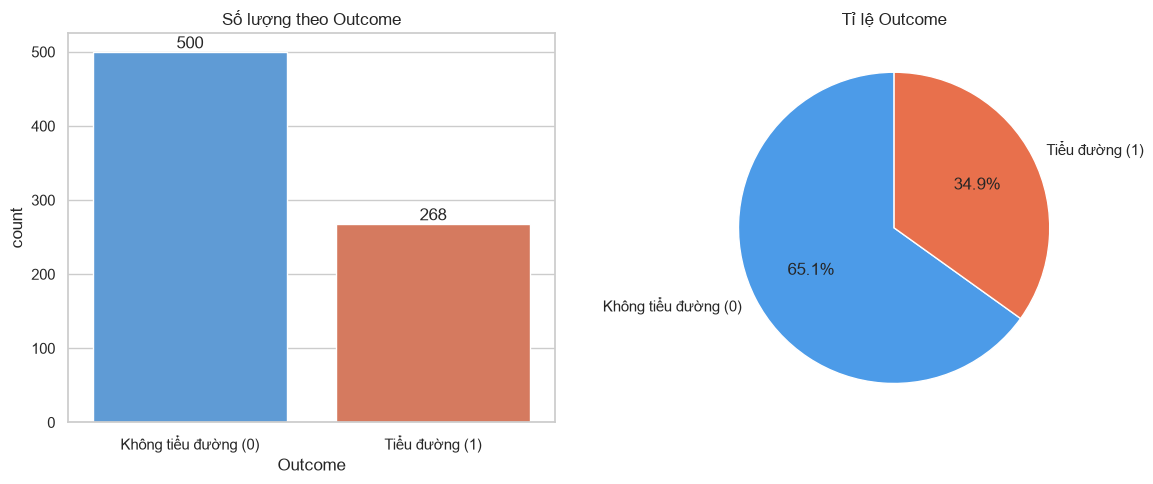

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cnt = diab_clean["Outcome"].value_counts().sort_index()
labels = ["Không tiểu đường (0)", "Tiểu đường (1)"]

sns.countplot(data=diab_clean, x="Outcome", ax=axes[0], palette=["#4c9be8", "#e8704c"])
axes[0].set_xticklabels(labels)
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set_title("Số lượng theo Outcome")

axes[1].pie(cnt, labels=labels, autopct="%1.1f%%", colors=["#4c9be8", "#e8704c"], startangle=90)
axes[1].set_title("Tỉ lệ Outcome")
plt.tight_layout(); plt.show()

### 2A.2 Histogram từng biến, tách theo `Outcome`

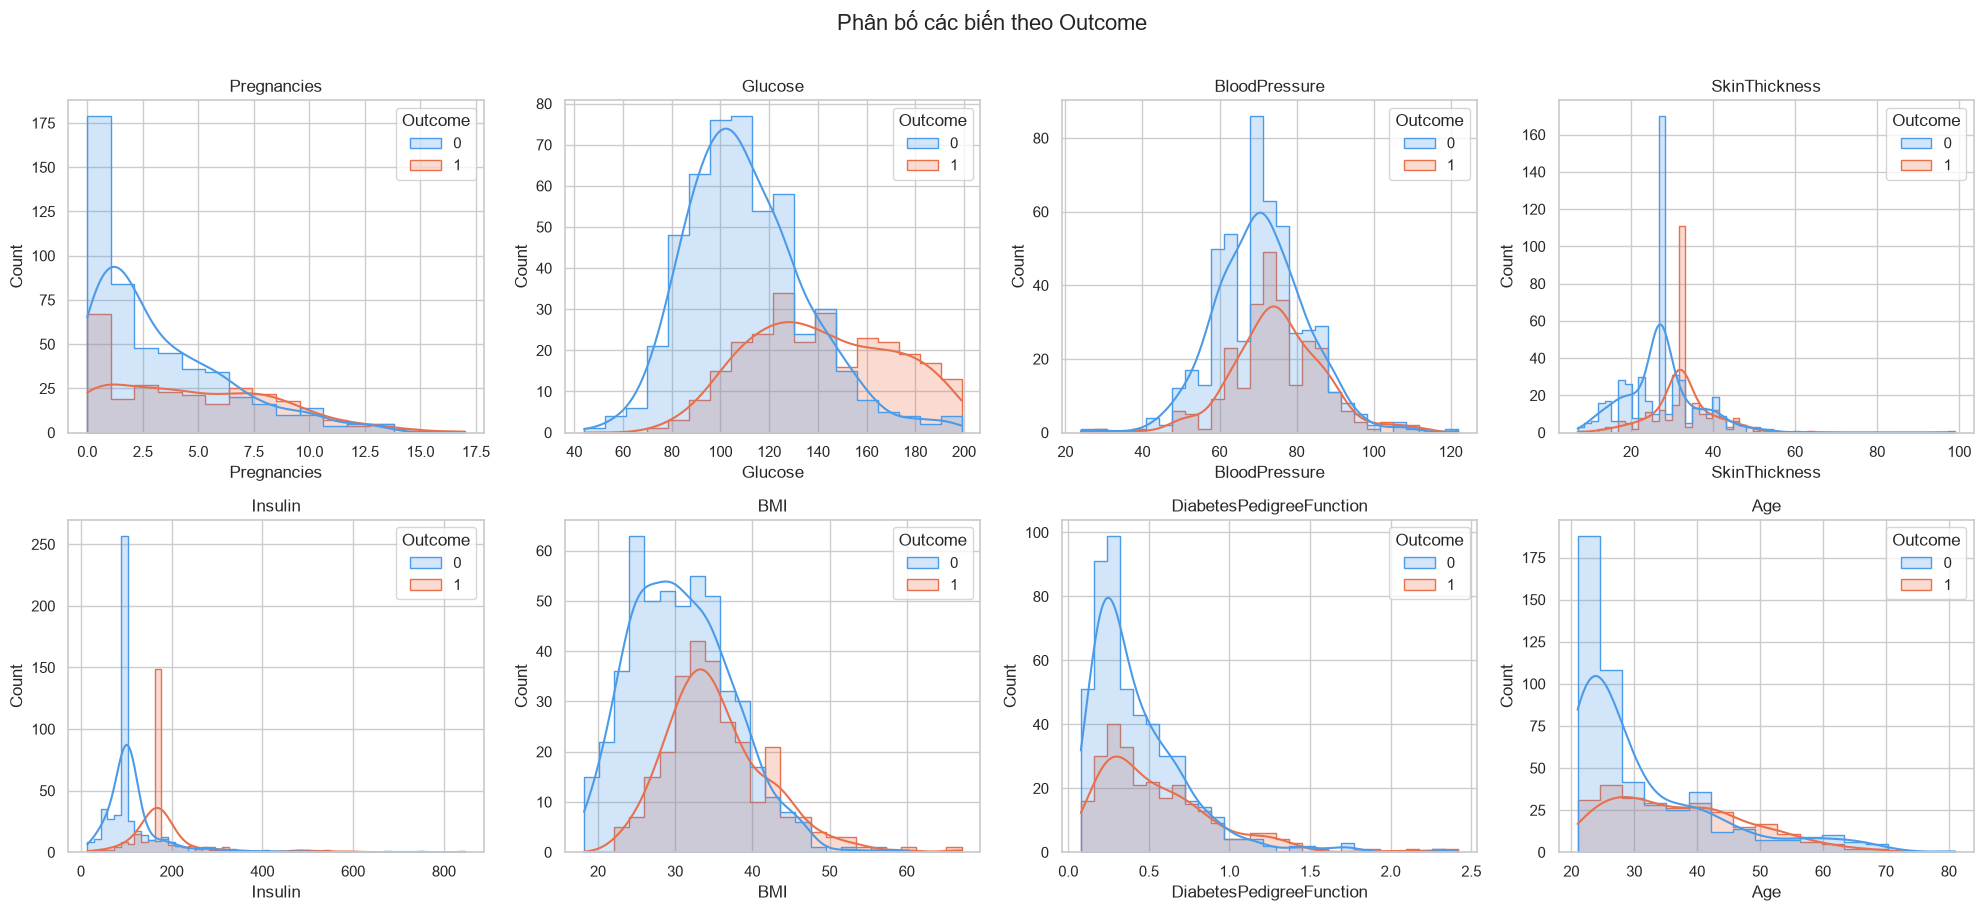

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=diab_clean, x=c, hue="Outcome", kde=True, element="step",
                 palette=["#4c9be8", "#e8704c"], ax=ax)
    ax.set_title(c)
plt.suptitle("Phân bố các biến theo Outcome", fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

### 2A.3 Boxplot & Violin plot theo `Outcome`

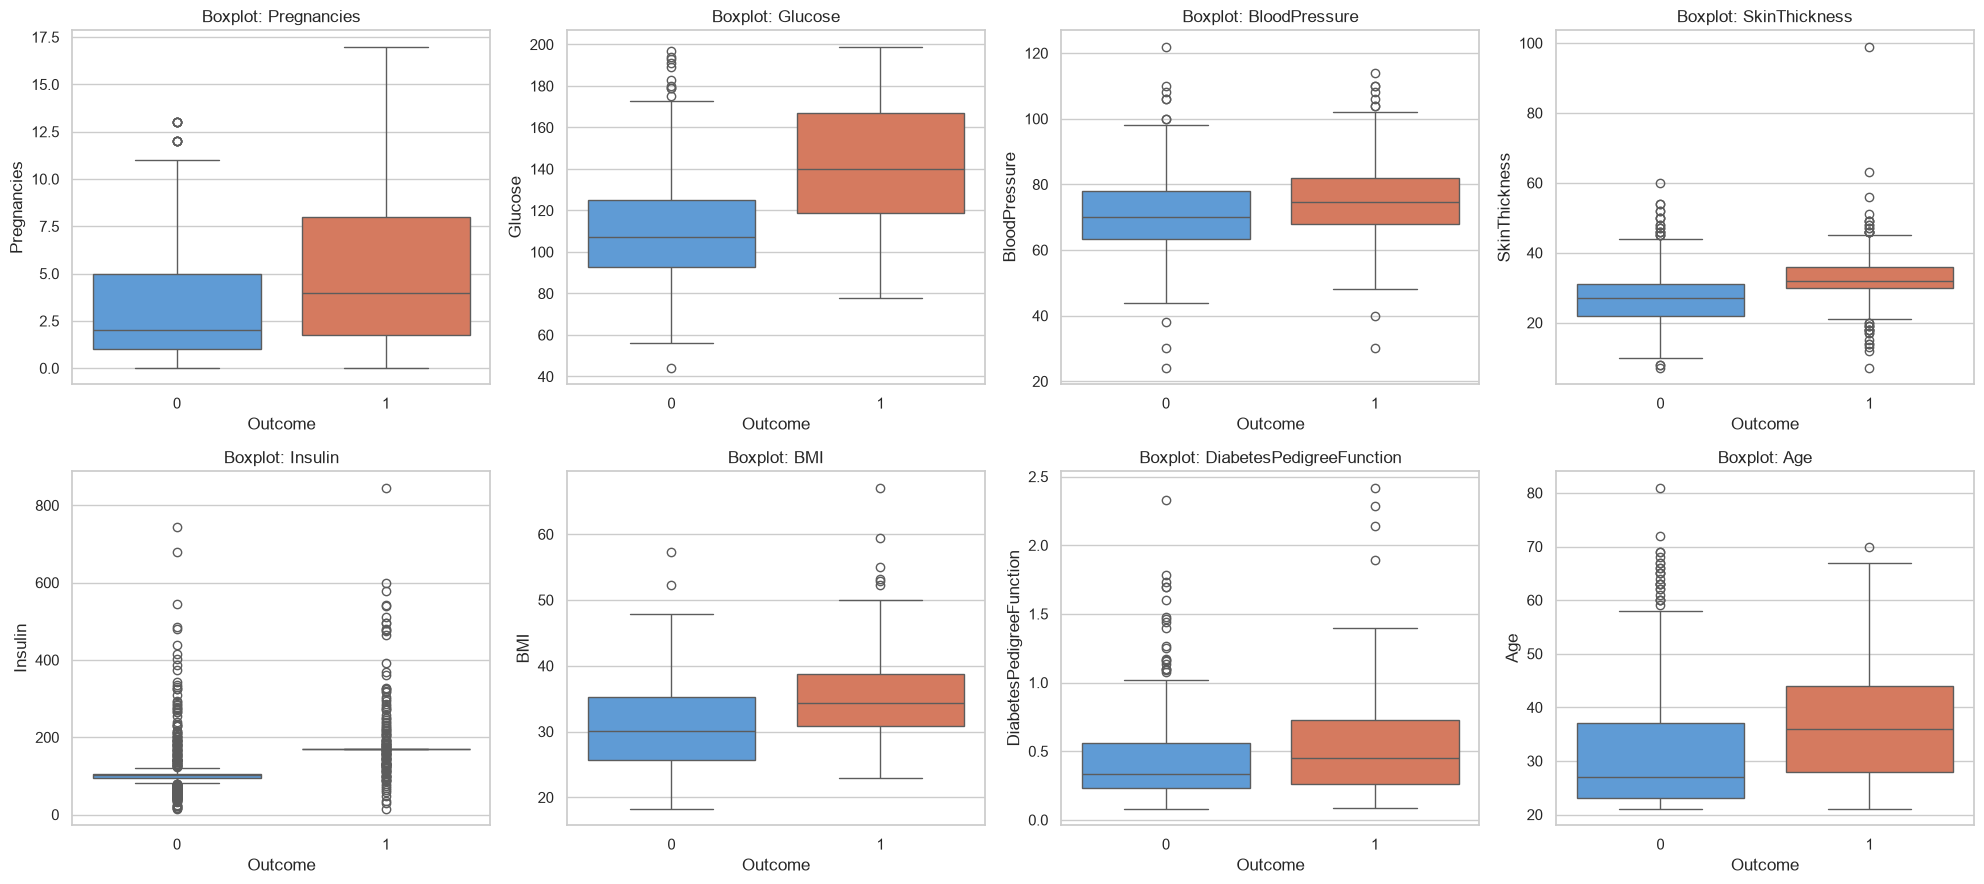

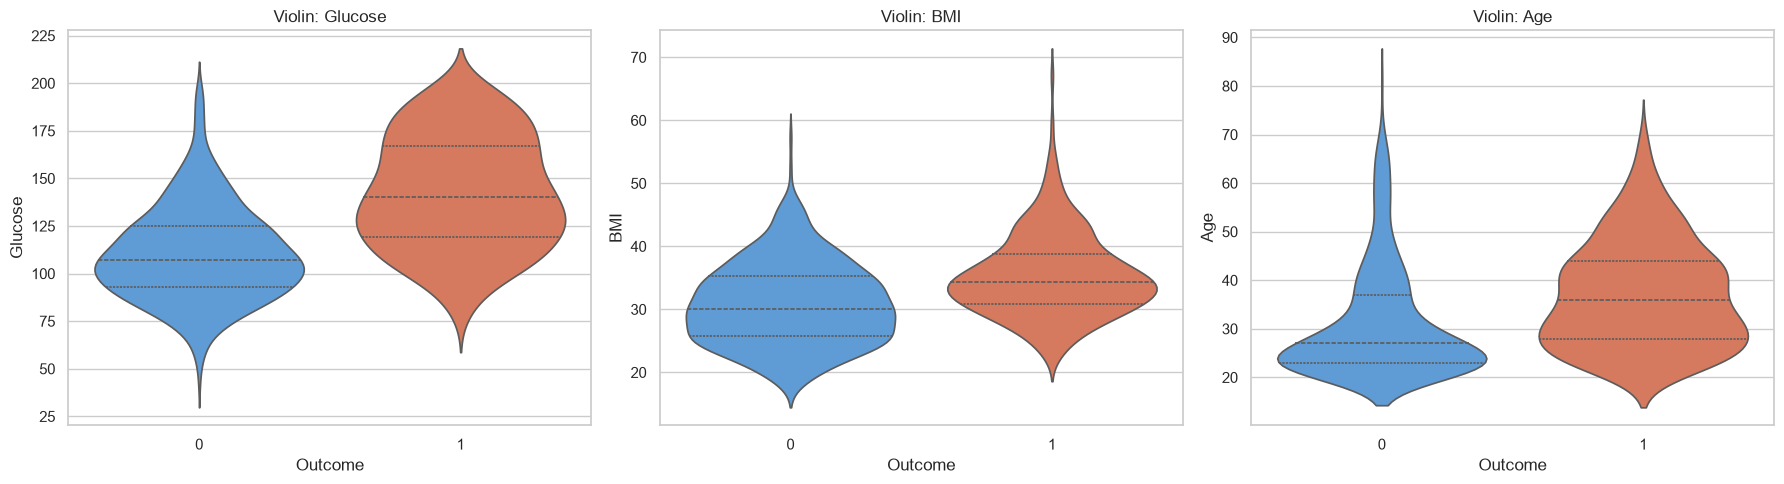

In [32]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=diab_clean, x="Outcome", y=c, ax=ax, palette=["#4c9be8", "#e8704c"])
    ax.set_title(f"Boxplot: {c}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.violinplot(data=diab_clean, x="Outcome", y=c, ax=ax, palette=["#4c9be8", "#e8704c"], inner="quartile")
    ax.set_title(f"Violin: {c}")
plt.tight_layout(); plt.show()

### 2A.4 Scatter plot & Pairplot

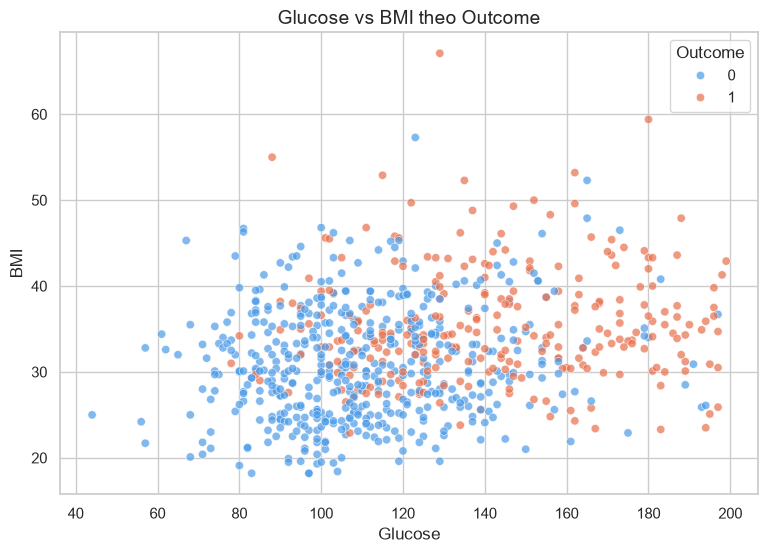

In [33]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=diab_clean, x="Glucose", y="BMI", hue="Outcome",
                palette=["#4c9be8", "#e8704c"], alpha=0.7)
plt.title("Glucose vs BMI theo Outcome", fontsize=14)
plt.show()

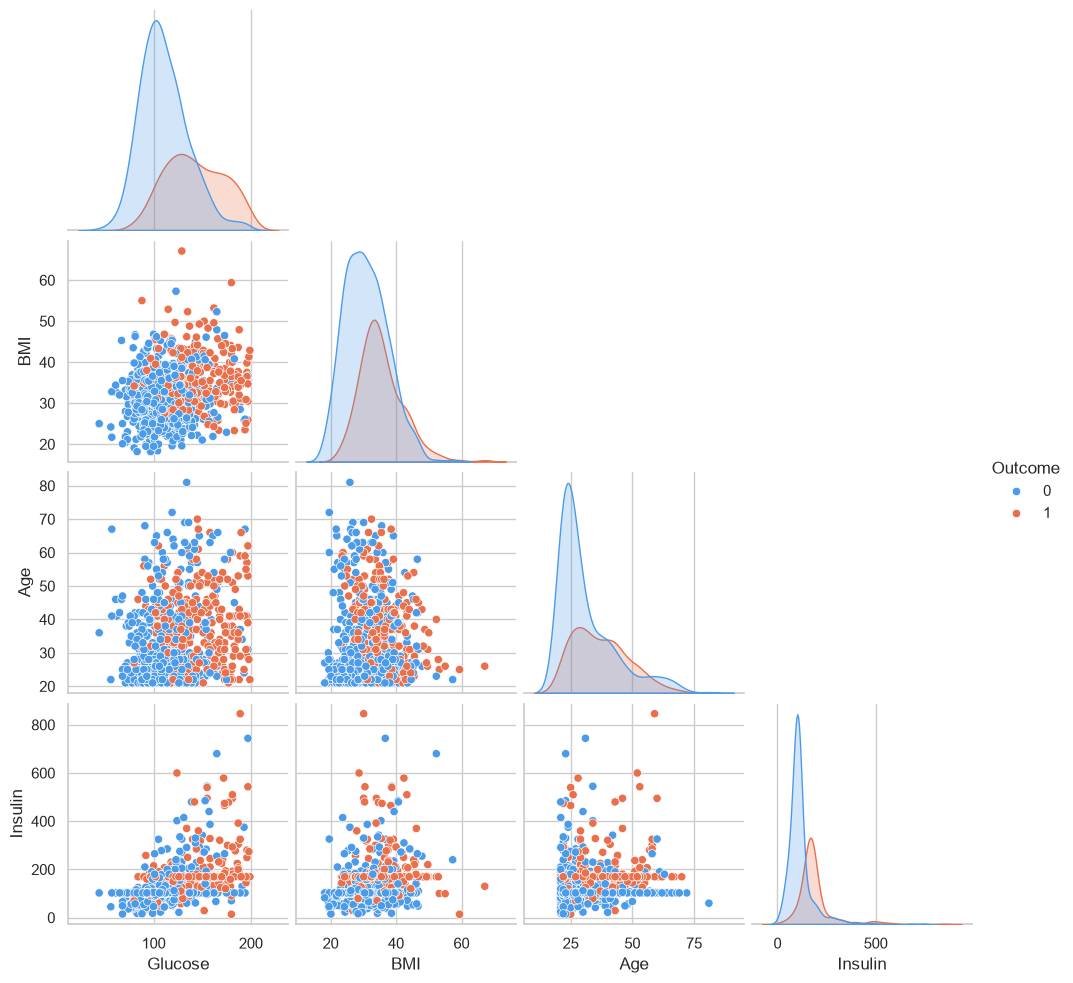

In [34]:
sns.pairplot(diab_clean[["Glucose", "BMI", "Age", "Insulin", "Outcome"]], hue="Outcome",
             palette=["#4c9be8", "#e8704c"], diag_kind="kde", corner=True)
plt.show()

### 2A.5 Heatmap tương quan

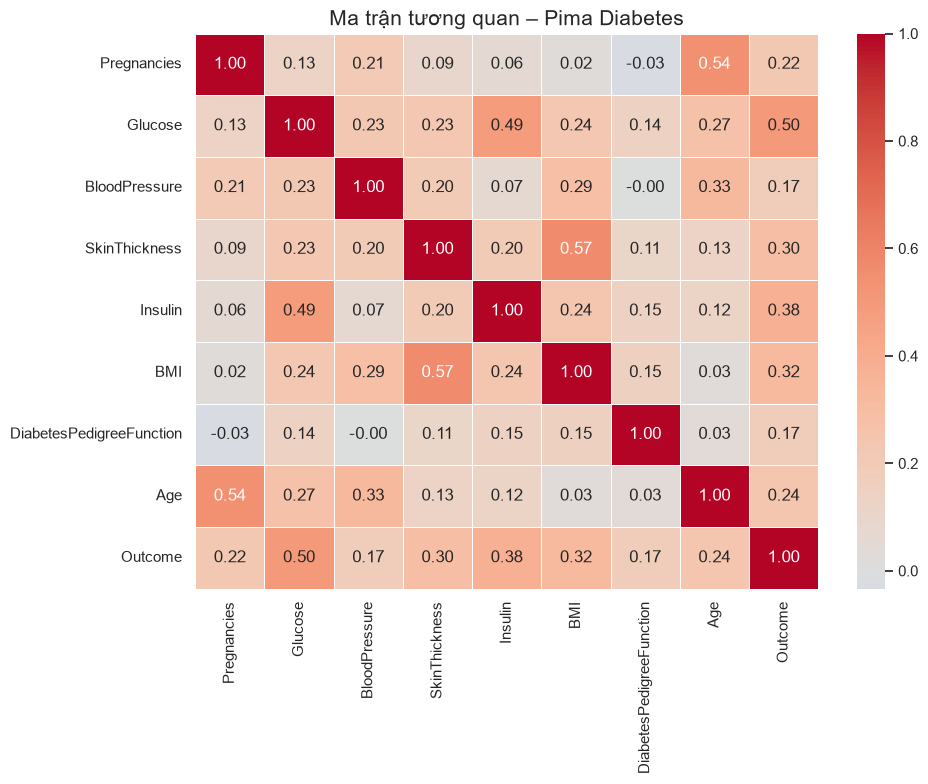

Glucose                     0.496
Insulin                     0.377
BMI                         0.316
SkinThickness               0.295
Age                         0.238
Pregnancies                 0.222
BloodPressure               0.174
DiabetesPedigreeFunction    0.174
Name: Outcome, dtype: float64

In [35]:
corr = diab_clean.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Ma trận tương quan – Pima Diabetes", fontsize=15)
plt.tight_layout(); plt.show()

corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

### 2A.6 Tỉ lệ tiểu đường theo nhóm tuổi và nhóm BMI

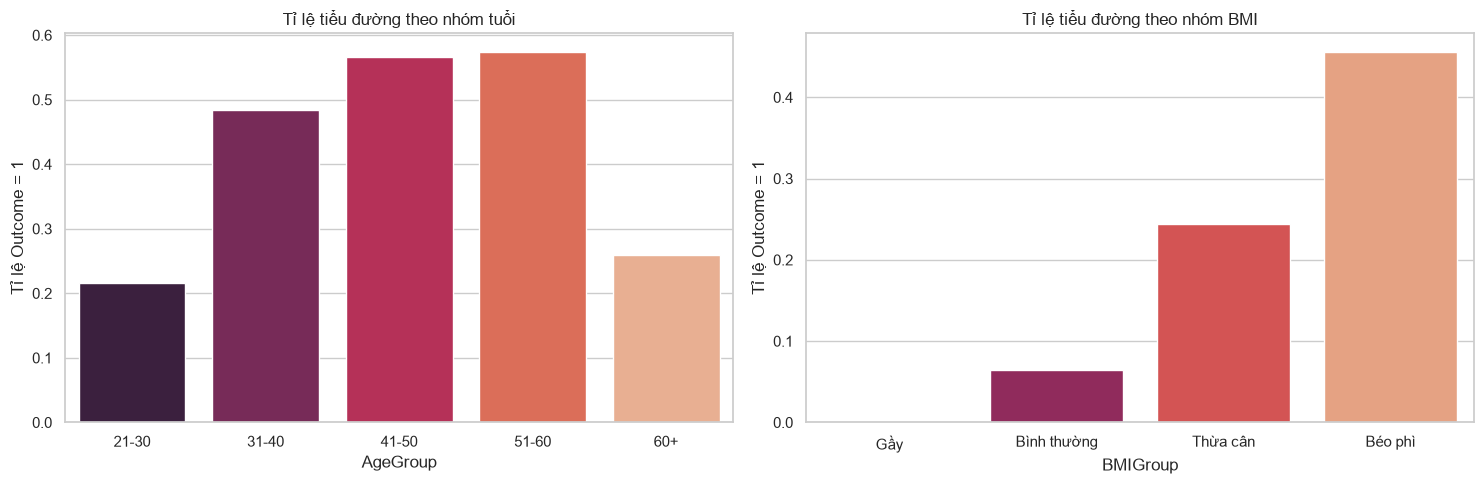

Outcome,0,1
AgeGroup,,
21-30,0.784,0.216
31-40,0.516,0.484
41-50,0.434,0.566
51-60,0.426,0.574
60+,0.741,0.259


In [36]:
d = diab_clean.copy()
d["AgeGroup"] = pd.cut(d["Age"], bins=[20, 30, 40, 50, 60, 100],
                       labels=["21-30", "31-40", "41-50", "51-60", "60+"])
d["BMIGroup"] = pd.cut(d["BMI"], bins=[0, 18.5, 25, 30, 100],
                       labels=["Gầy", "Bình thường", "Thừa cân", "Béo phì"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=d, x="AgeGroup", y="Outcome", ax=axes[0], palette="rocket", errorbar=None)
axes[0].set_title("Tỉ lệ tiểu đường theo nhóm tuổi"); axes[0].set_ylabel("Tỉ lệ Outcome = 1")
sns.barplot(data=d, x="BMIGroup", y="Outcome", ax=axes[1], palette="rocket", errorbar=None)
axes[1].set_title("Tỉ lệ tiểu đường theo nhóm BMI"); axes[1].set_ylabel("Tỉ lệ Outcome = 1")
plt.tight_layout(); plt.show()

pd.crosstab(d["AgeGroup"], d["Outcome"], normalize="index").round(3)

---
## 2B. EDA TẬP DỮ LIỆU MUA SẮM SIÊU THỊ – ONLINE RETAIL
Cột: `InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country`.
### 2B.1 Nạp dữ liệu

In [37]:
def load_retail():
    for name in ["Online_Retail.xlsx", "Online Retail.xlsx"]:
        try:
            return pd.read_excel(find_file(name), sheet_name=0)   # cần: pip install openpyxl
        except FileNotFoundError:
            pass
    for name in ["OnlineRetail.csv", "Online Retail.csv", "data.csv"]:
        try:
            return pd.read_csv(find_file(name), encoding="ISO-8859-1")
        except FileNotFoundError:
            pass
    raise FileNotFoundError("Không tìm thấy dữ liệu Online Retail trong ./data")

retail = load_retail()
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"])
print("Kích thước:", retail.shape)
retail.head()

Kích thước: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [38]:
retail.info()
print("\nGiá trị thiếu:\n", retail.isnull().sum())
print("\nDòng trùng:", retail.duplicated().sum())
retail.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Giá trị thiếu:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Dòng trùng: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2B.2 Làm sạch dữ liệu
- Bỏ dòng trùng lặp
- Bỏ hóa đơn bị hủy (`InvoiceNo` bắt đầu bằng `C`) và các dòng `Quantity <= 0` hoặc `UnitPrice <= 0`
- Giữ lại dòng thiếu `CustomerID` cho phân tích doanh thu nói chung (nhưng loại khi phân tích khách hàng)

In [39]:
r = retail.drop_duplicates().copy()
r["InvoiceNo"] = r["InvoiceNo"].astype(str)
n0 = len(r)

cancelled = r["InvoiceNo"].str.startswith("C")
print("Số dòng hóa đơn hủy:", cancelled.sum())

r = r[~cancelled & (r["Quantity"] > 0) & (r["UnitPrice"] > 0)]
print(f"Số dòng: {n0} -> {len(r)}")

# Thêm các biến dẫn xuất
r["Revenue"] = r["Quantity"] * r["UnitPrice"]
r["Year"] = r["InvoiceDate"].dt.year
r["Month"] = r["InvoiceDate"].dt.to_period("M").astype(str)
r["DayOfWeek"] = r["InvoiceDate"].dt.day_name()
r["Hour"] = r["InvoiceDate"].dt.hour
r[["Quantity", "UnitPrice", "Revenue"]].describe().round(2)

Số dòng hóa đơn hủy: 9251
Số dòng: 536641 -> 524878


,Quantity,UnitPrice,Revenue
count,524878.00,524878.00,524878.00
mean,10.62,3.92,20.28
std,156.28,36.09,271.69
min,1.00,0.00,0.00
25%,1.00,1.25,3.90
50%,4.00,2.08,9.92
75%,11.00,4.13,17.70
max,80995.00,13541.33,168469.60


### 2B.3 Doanh thu theo quốc gia

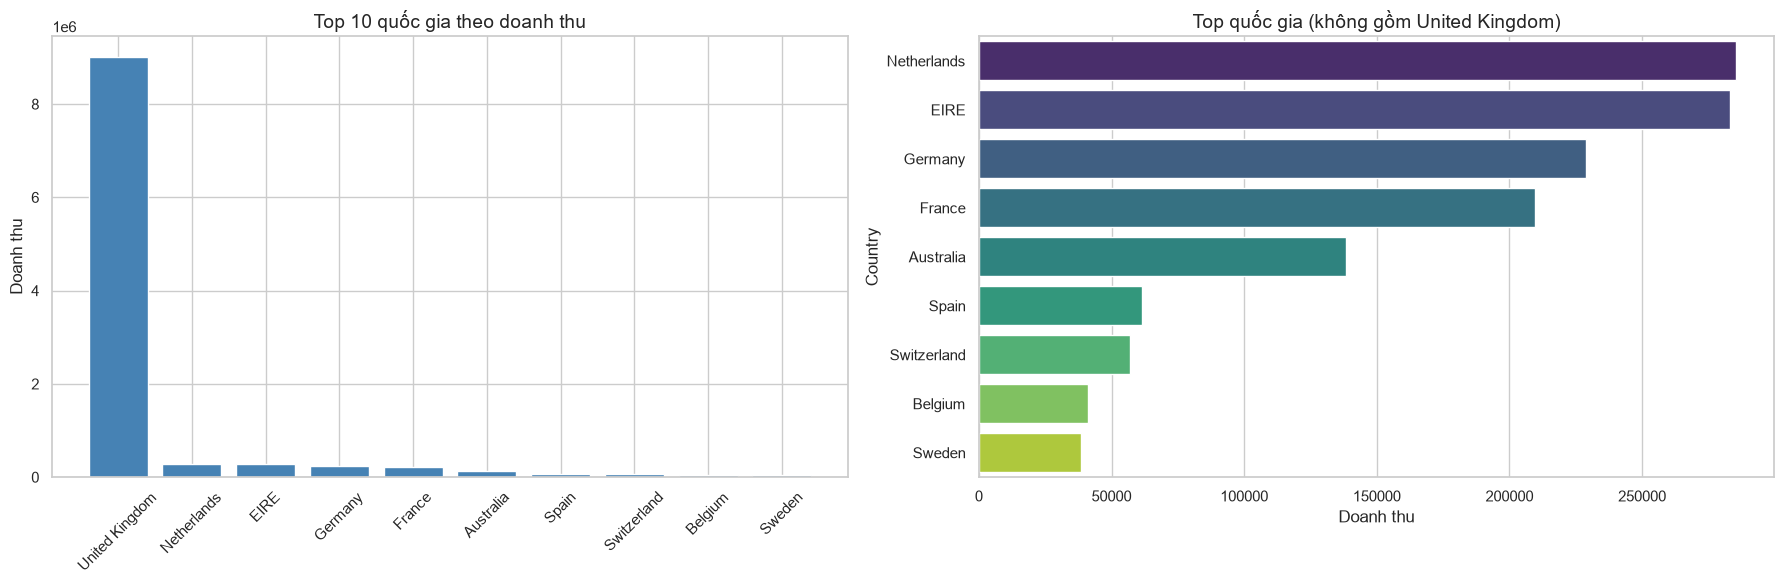

Tỉ trọng doanh thu của UK: 84.6%


In [40]:
by_country = r.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
top10 = by_country.head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].bar(top10.index, top10.values, color="steelblue")
axes[0].set_title("Top 10 quốc gia theo doanh thu", fontsize=14)
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Doanh thu")

no_uk = top10.drop("United Kingdom", errors="ignore")
sns.barplot(x=no_uk.values, y=no_uk.index, ax=axes[1], palette="viridis")
axes[1].set_title("Top quốc gia (không gồm United Kingdom)", fontsize=14)
axes[1].set_xlabel("Doanh thu")
plt.tight_layout(); plt.show()

print("Tỉ trọng doanh thu của UK: {:.1%}".format(by_country.get("United Kingdom", 0) / by_country.sum()))

### 2B.4 Sản phẩm bán chạy

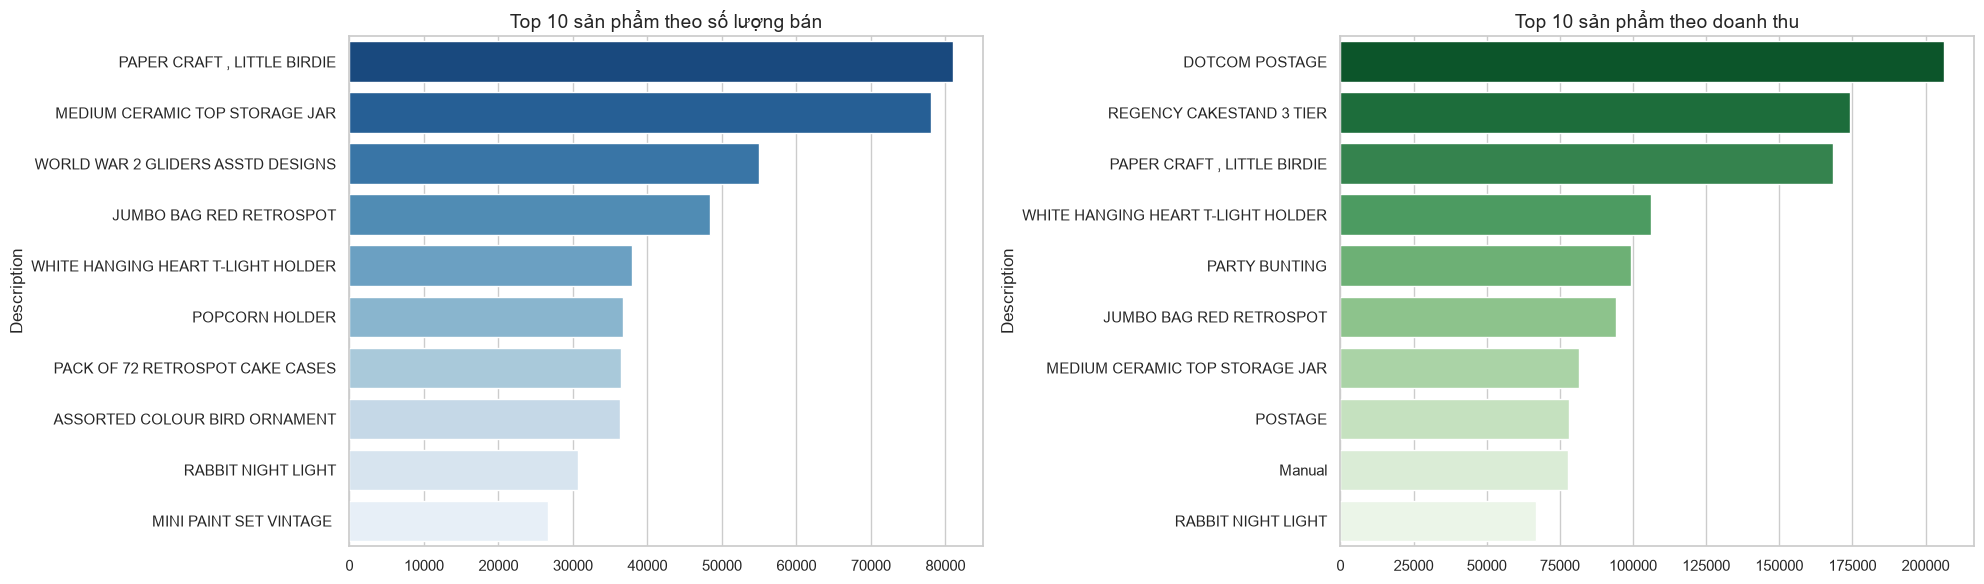

In [41]:
top_qty = r.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
top_rev = r.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.barplot(x=top_qty.values, y=top_qty.index, ax=axes[0], palette="Blues_r")
axes[0].set_title("Top 10 sản phẩm theo số lượng bán", fontsize=14)
sns.barplot(x=top_rev.values, y=top_rev.index, ax=axes[1], palette="Greens_r")
axes[1].set_title("Top 10 sản phẩm theo doanh thu", fontsize=14)
plt.tight_layout(); plt.show()

### 2B.5 Xu hướng theo thời gian

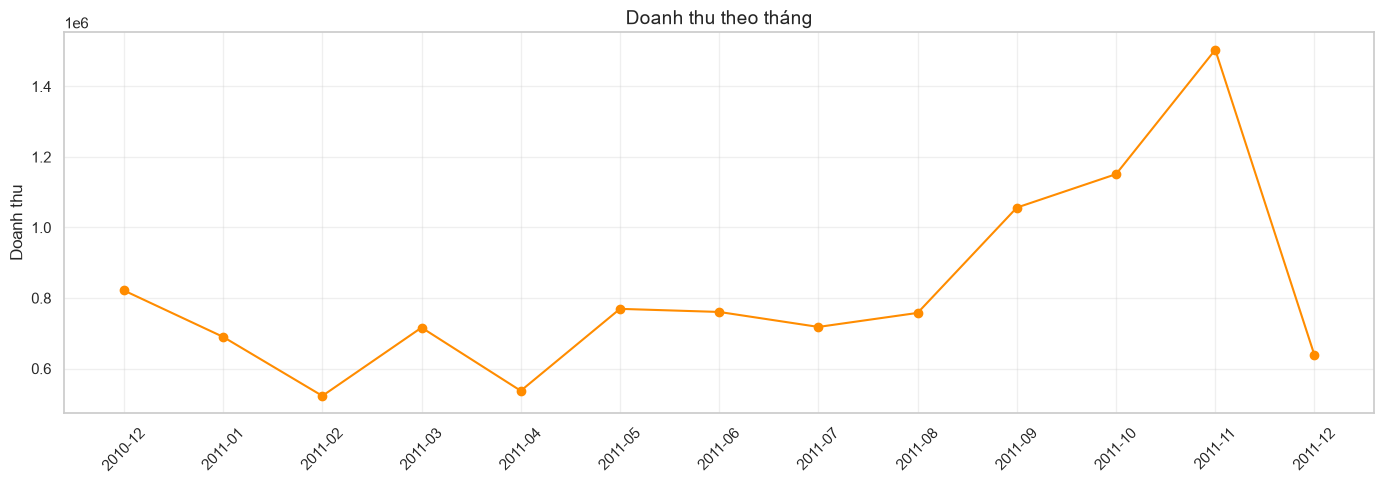

In [42]:
monthly = r.groupby("Month")["Revenue"].sum()
plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="darkorange")
plt.title("Doanh thu theo tháng", fontsize=14)
plt.xticks(rotation=45); plt.ylabel("Doanh thu"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

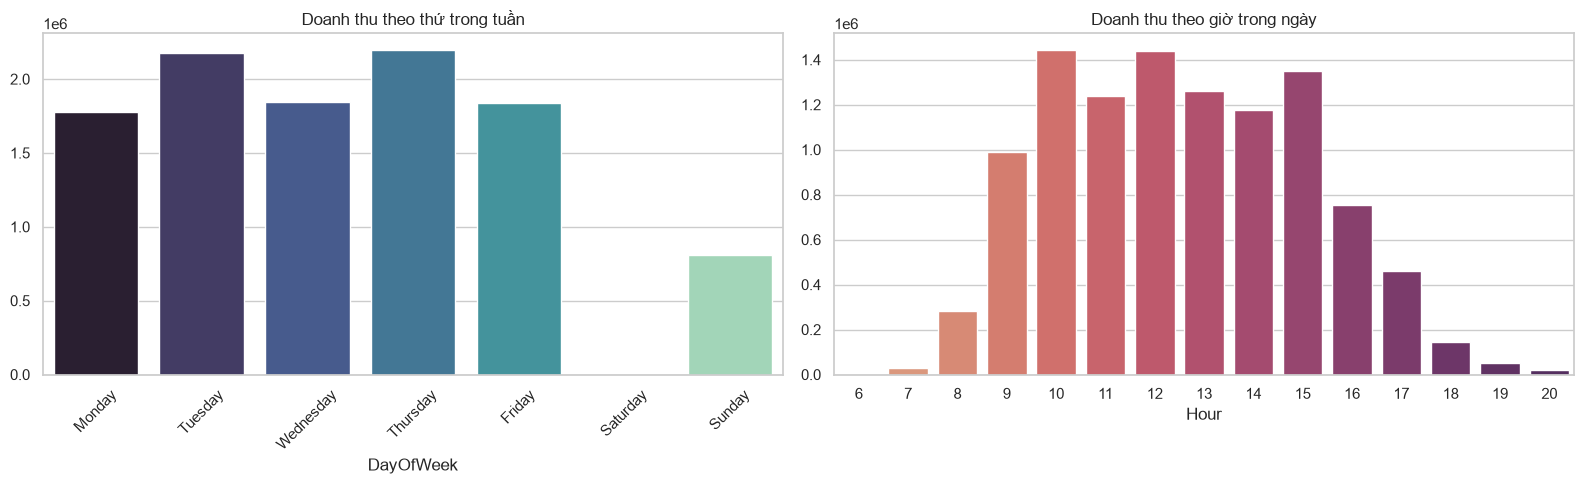

In [43]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = r.groupby("DayOfWeek")["Revenue"].sum().reindex(order)
hour = r.groupby("Hour")["Revenue"].sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=dow.index, y=dow.values, ax=axes[0], palette="mako")
axes[0].set_title("Doanh thu theo thứ trong tuần"); axes[0].tick_params(axis="x", rotation=45)
sns.barplot(x=hour.index, y=hour.values, ax=axes[1], palette="flare")
axes[1].set_title("Doanh thu theo giờ trong ngày")
plt.tight_layout(); plt.show()

### 2B.6 Phân bố `Quantity`, `UnitPrice`, `Revenue` (dùng log do lệch phải mạnh)

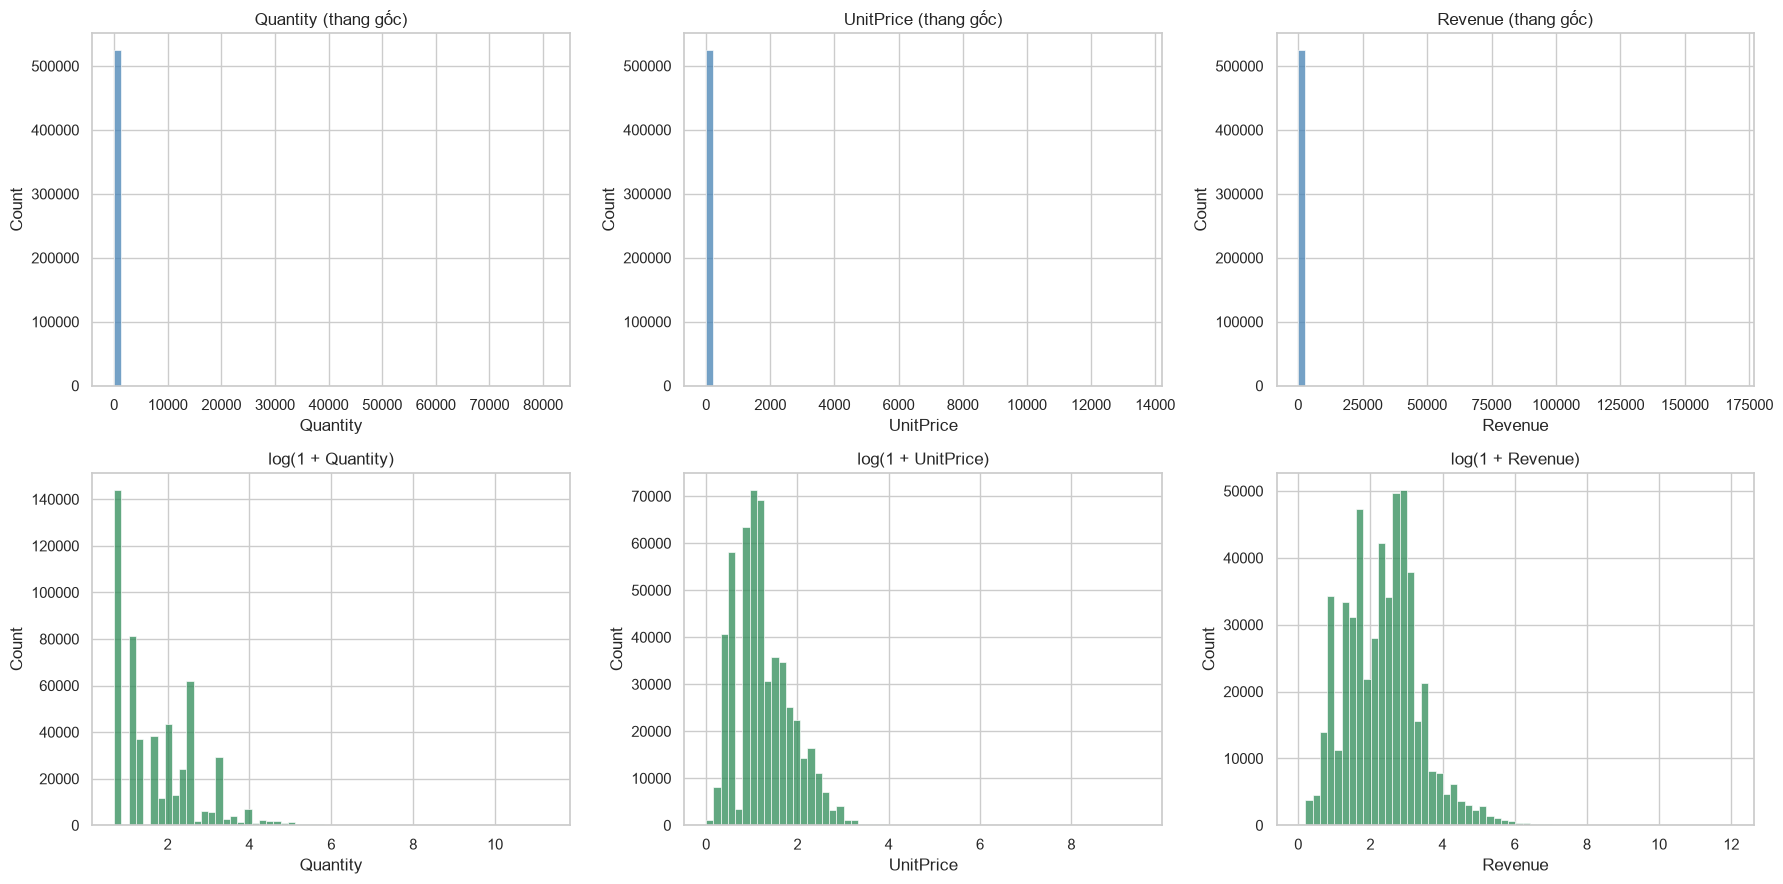

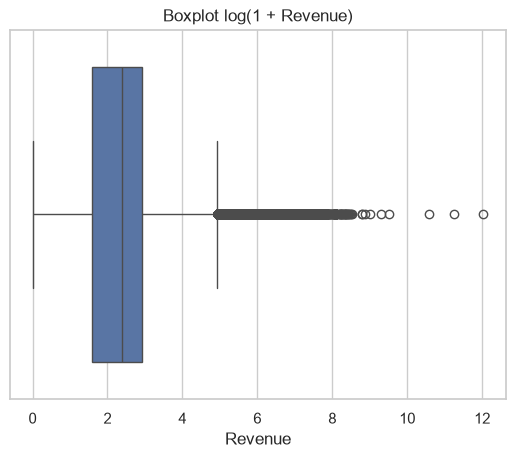

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for i, c in enumerate(["Quantity", "UnitPrice", "Revenue"]):
    sns.histplot(r[c], bins=60, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"{c} (thang gốc)")
    sns.histplot(np.log1p(r[c]), bins=60, ax=axes[1, i], color="seagreen")
    axes[1, i].set_title(f"log(1 + {c})")
plt.tight_layout(); plt.show()

sns.boxplot(x=np.log1p(r["Revenue"]))
plt.title("Boxplot log(1 + Revenue)")
plt.show()

### 2B.7 Phân tích khách hàng

Số khách hàng: 4338
        so_don    tong_sl  doanh_thu
count  4338.00    4338.00    4338.00
mean      4.27    1187.64    2048.69
std       7.70    5043.62    8985.23
min       1.00       1.00       3.75
25%       1.00     159.00     306.48
50%       2.00     378.00     668.57
75%       5.00     989.75    1660.60
max     209.00  196915.00  280206.02


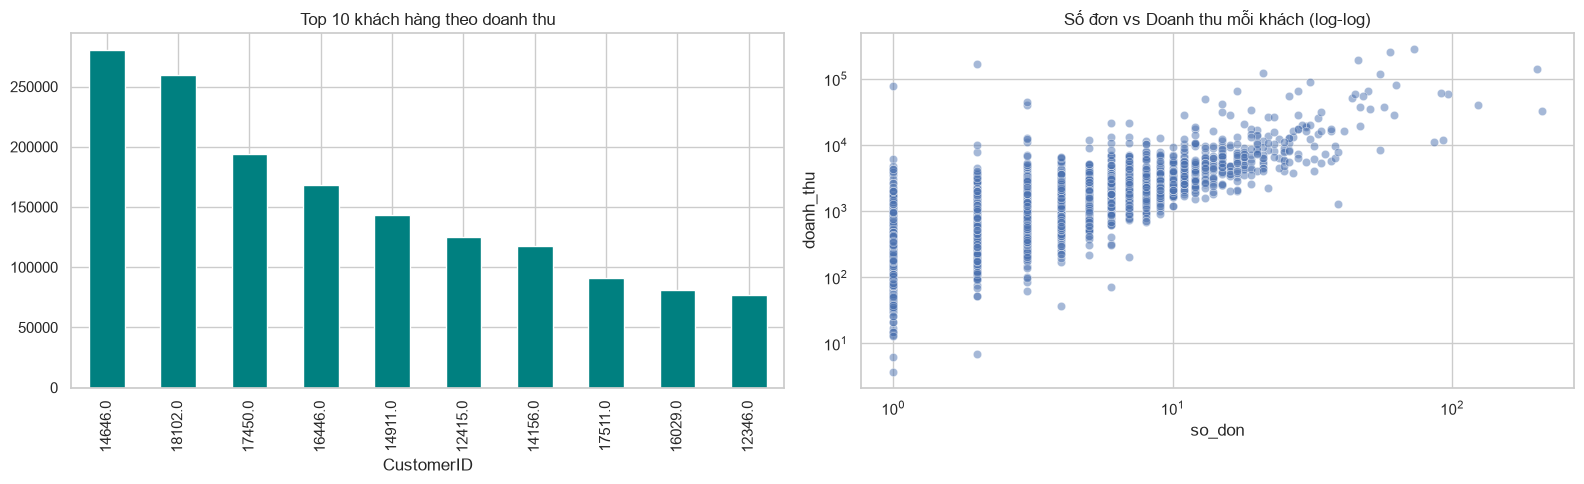

In [45]:
cust = r.dropna(subset=["CustomerID"])
cust_stat = cust.groupby("CustomerID").agg(
    so_don=("InvoiceNo", "nunique"),
    tong_sl=("Quantity", "sum"),
    doanh_thu=("Revenue", "sum")
)
print("Số khách hàng:", len(cust_stat))
print(cust_stat.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
cust_stat["doanh_thu"].sort_values(ascending=False).head(10).plot(kind="bar", ax=axes[0], color="teal")
axes[0].set_title("Top 10 khách hàng theo doanh thu")
sns.scatterplot(data=cust_stat, x="so_don", y="doanh_thu", alpha=0.5, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Số đơn vs Doanh thu mỗi khách (log-log)")
plt.tight_layout(); plt.show()

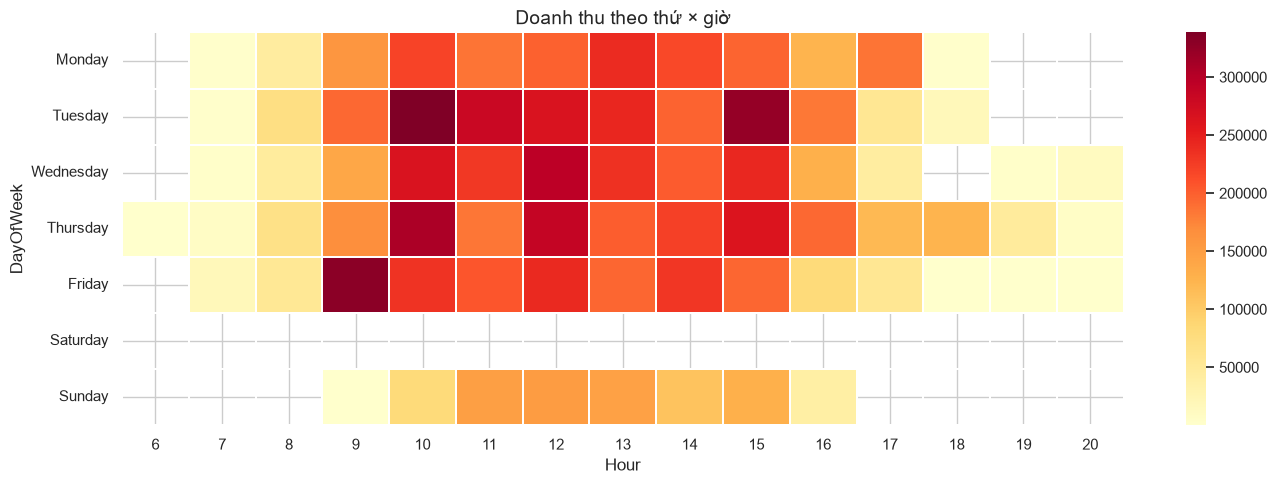

In [46]:
# Heatmap: doanh thu theo thứ x giờ
pivot = r.pivot_table(index="DayOfWeek", columns="Hour", values="Revenue", aggfunc="sum").reindex(order)
plt.figure(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.3)
plt.title("Doanh thu theo thứ × giờ", fontsize=14)
plt.tight_layout(); plt.show()

### 2B.8 Xuất biểu đồ ra file

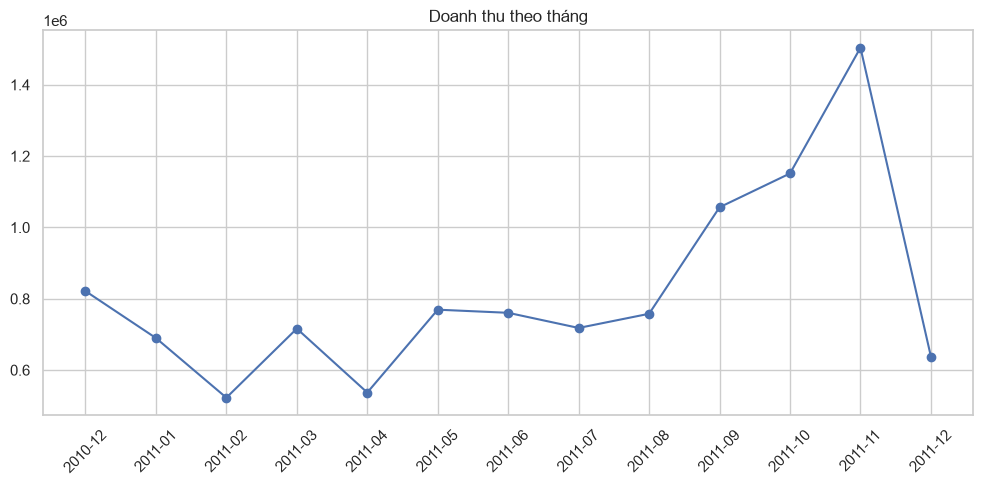

In [47]:
os.makedirs("outputs", exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Doanh thu theo tháng"); ax.tick_params(axis="x", rotation=45)
fig.savefig("outputs/retail_monthly_revenue.png", dpi=300, bbox_inches="tight")
fig.savefig("outputs/retail_monthly_revenue.pdf", bbox_inches="tight")
plt.show()

---
# PHẦN 3. CÔNG CỤ EDA TỰ ĐỘNG – AUTOVIZ (Marketing Campaign)
**AutoViz** tự động vẽ nhiều loại biểu đồ (histogram, boxplot, scatter, heatmap tương quan, violin…) chỉ với một lệnh, kèm phát hiện vấn đề chất lượng dữ liệu.

Cài đặt: `pip install autoviz`

In [48]:
mk = pd.read_csv(find_file("marketing_campaign.csv"), sep="\t")
if mk.shape[1] == 1:
    mk = pd.read_csv(find_file("marketing_campaign.csv"), sep=";")
mk["Dt_Customer"] = pd.to_datetime(mk["Dt_Customer"], dayfirst=True, errors="coerce")
print(mk.shape)
mk.head()
print("Giá trị thiếu:", mk.isnull().sum()[mk.isnull().sum() > 0].to_dict())   # Income thiếu 24 dòng


(2240, 29)
Giá trị thiếu: {'Income': 24}


## 3.1 Chạy AutoViz

In [49]:
from autoviz.AutoViz_Class import AutoViz_Class

AV = AutoViz_Class()
report = AV.AutoViz(
    filename="",          # để trống vì truyền trực tiếp DataFrame
    dfte=mk,
    depVar="Response",    # biến mục tiêu (có thể để "" nếu không cần)
    verbose=1,            # 0: ít thông tin, 1: đầy đủ biểu đồ, 2: lưu biểu đồ vào file
    chart_format="png",   # 'png', 'svg', 'html', 'bokeh'
    max_rows_analyzed=150000,
    max_cols_analyzed=30,
)

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (2240, 29)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
Education of type=str is not classified
Marital_Status of type=str is not classified
Dt_Customer of type=datetime64[us] is not classified
    Number of Numeric Columns =  1
    Number of Integer-Categorical Columns =  15
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  

AttributeError: 'DataFrame' object has no attribute 'applymap'

## 3.2 Chỉ phân tích một nhóm cột & lưu biểu đồ

In [ ]:
cols = ["Year_Birth", "Income", "Kidhome", "Teenhome", "Recency",
        "NumStorePurchases", "NumWebVisitsMonth", "Response"]

report2 = AV.AutoViz(
    filename="",
    dfte=mk[cols],
    depVar="Response",
    verbose=2,                  # lưu biểu đồ vào thư mục AutoViz_Plots
    chart_format="html",
)
print("Biểu đồ được lưu trong thư mục AutoViz_Plots/")

## 3.3 Tìm hiểu tính năng AutoViz – ghi chú (điền sau khi chạy)
| Tham số/tính năng | Ý nghĩa |
|---|---|
| `dfte` / `filename` | Truyền DataFrame hoặc đường dẫn file |
| `depVar` | Biến mục tiêu – AutoViz vẽ quan hệ các biến với target |
| `verbose` | 0: chỉ cảnh báo, 1: hiển thị biểu đồ, 2: lưu biểu đồ |
| `chart_format` | `png`, `svg`, `html`, `bokeh`, `server` |
| `max_rows_analyzed`, `max_cols_analyzed` | Lấy mẫu để chạy nhanh với dữ liệu lớn |
| Data Cleaning Suggestions | Gợi ý xử lý thiếu, ngoại lai, cột hằng số, tương quan cao |

